In [ ]:
from pathlib import Path
import os

# notebooks live in ai/notebooks/; data paths are relative to ai/
os.chdir(Path("..").resolve())


# copy region, lesion insert, jpeg

Three more attacks on the real images from `metadata/split.csv`:

- **copy_region** — copy an elliptical patch from one place in the image to another (soft blend)
- **lesion_insert** — take a bright patch from a tumor image and blend it into the target
- **jpeg** — recompress at quality 40, **test split only**, held out of training

Seed is 42. Fakes keep the same split as their real image. Then everything (real + noise/gamma + these) goes into `metadata/manifest.csv`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

split_df = pd.read_csv("metadata/split.csv")
SEED = 42
JPEG_QUALITY = 40
out_root = Path("fake")

tumor_paths = split_df.loc[split_df.folder != "notumor", "path"].tolist()
len(split_df), len(tumor_paths)

(7200, 5400)

In [2]:
def save_jpg(img, path, quality=95):
    for _ in range(5):
        try:
            img.save(path, quality=quality)
            return
        except PermissionError:
            time.sleep(0.3)
    img.save(path, quality=quality)


def soft_ellipse(h, w, cy, cx, ry, rx):
    yy, xx = np.ogrid[:h, :w]
    dist = ((yy - cy) / max(ry, 1.0)) ** 2 + ((xx - cx) / max(rx, 1.0)) ** 2
    mask = np.zeros((h, w), dtype=np.float32)
    inner = dist <= 0.55
    ring = (dist > 0.55) & (dist <= 1.0)
    mask[inner] = 1.0
    mask[ring] = ((1.0 - dist[ring]) / 0.45) ** 2
    return mask


def random_center(rng, h, w, ry, rx, margin=4):
    cy = int(rng.integers(ry + margin, h - ry - margin))
    cx = int(rng.integers(rx + margin, w - rx - margin))
    return cy, cx


def copy_region(img, rng):
    arr = np.asarray(img).astype(np.float32)
    h, w = arr.shape[:2]
    side = int(min(h, w) * float(rng.uniform(0.12, 0.22)))
    ry = rx = max(side // 2, 8)
    sy, sx = random_center(rng, h, w, ry, rx)
    for _ in range(20):
        dy, dx = random_center(rng, h, w, ry, rx)
        if (dy - sy) ** 2 + (dx - sx) ** 2 >= (ry * 1.5) ** 2:
            break
    dst_mask = soft_ellipse(h, w, dy, dx, ry, rx)
    # shift source content onto destination coordinates
    shifted = np.zeros_like(arr)
    yy, xx = np.nonzero(dst_mask > 0)
    src_y = np.clip(yy - dy + sy, 0, h - 1)
    src_x = np.clip(xx - dx + sx, 0, w - 1)
    if arr.ndim == 3:
        shifted[yy, xx] = arr[src_y, src_x]
        alpha = dst_mask[..., None]
    else:
        shifted[yy, xx] = arr[src_y, src_x]
        alpha = dst_mask
    out = arr * (1.0 - alpha) + shifted * alpha
    return Image.fromarray(np.clip(out, 0, 255).astype(np.uint8)), float(side)


def brightest_center(gray, rng, ry, rx, tries=12):
    h, w = gray.shape
    best = None
    best_score = -1.0
    for _ in range(tries):
        cy, cx = random_center(rng, h, w, ry, rx)
        mask = soft_ellipse(h, w, cy, cx, ry, rx)
        score = float((gray * mask).sum() / (mask.sum() + 1e-6))
        if score > best_score:
            best_score = score
            best = (cy, cx)
    return best


def lesion_insert(host_img, donor_img, rng):
    host = np.asarray(host_img).astype(np.float32)
    donor = np.asarray(donor_img).astype(np.float32)
    h, w = host.shape[:2]
    dh, dw = donor.shape[:2]
    side = int(min(h, w, dh, dw) * float(rng.uniform(0.10, 0.18)))
    ry = rx = max(side // 2, 8)
    donor_gray = donor.mean(axis=2) if donor.ndim == 3 else donor
    sy, sx = brightest_center(donor_gray, rng, ry, rx)
    dy, dx = random_center(rng, h, w, ry, rx)
    dst_mask = soft_ellipse(h, w, dy, dx, ry, rx)
    patch = np.zeros_like(host)
    yy, xx = np.nonzero(dst_mask > 0)
    src_y = np.clip(yy - dy + sy, 0, dh - 1)
    src_x = np.clip(xx - dx + sx, 0, dw - 1)
    if host.ndim == 3:
        patch[yy, xx] = donor[src_y, src_x]
        alpha = (dst_mask * 0.85)[..., None]
    else:
        patch[yy, xx] = donor[src_y, src_x] if donor.ndim == 2 else donor_gray[src_y, src_x]
        alpha = dst_mask * 0.85
    out = host * (1.0 - alpha) + patch * alpha
    return Image.fromarray(np.clip(out, 0, 255).astype(np.uint8)), float(side)


rng = np.random.default_rng(SEED)
records = []

for i, row in split_df.iterrows():
    src = Path(row.path)
    rel = src.relative_to("data")
    copy_path = out_root / "copy_region" / rel
    lesion_path = out_root / "lesion_insert" / rel
    copy_path.parent.mkdir(parents=True, exist_ok=True)
    lesion_path.parent.mkdir(parents=True, exist_ok=True)

    # advance donor choice every row so seed stays stable even when skipping
    donor_path = Path(tumor_paths[int(rng.integers(0, len(tumor_paths)))])
    while donor_path.as_posix() == row.path and len(tumor_paths) > 1:
        donor_path = Path(tumor_paths[int(rng.integers(0, len(tumor_paths)))])

    if copy_path.exists() and lesion_path.exists():
        # burn the same RNG draws the generate branch would use
        img = Image.open(src).convert("RGB")
        _, copy_param = copy_region(img, rng)
        donor = Image.open(donor_path).convert("RGB")
        _, lesion_param = lesion_insert(img, donor, rng)
    else:
        img = Image.open(src).convert("RGB")
        copy_img, copy_param = copy_region(img, rng)
        donor = Image.open(donor_path).convert("RGB")
        lesion_img, lesion_param = lesion_insert(img, donor, rng)
        save_jpg(copy_img, copy_path)
        save_jpg(lesion_img, lesion_path)

    records.append({
        "real_path": row.path,
        "fake_path": copy_path.as_posix(),
        "attack": "copy_region",
        "param": copy_param,
        "folder": row.folder,
        "split": row.split,
        "seed": SEED,
        "held_out": False,
        "donor_path": "",
    })
    records.append({
        "real_path": row.path,
        "fake_path": lesion_path.as_posix(),
        "attack": "lesion_insert",
        "param": lesion_param,
        "folder": row.folder,
        "split": row.split,
        "seed": SEED,
        "held_out": False,
        "donor_path": donor_path.as_posix(),
    })

    if (i + 1) % 1000 == 0:
        print(i + 1, "images")

extra = pd.DataFrame(records)
print("copy/lesion rows", len(extra))
extra.attack.value_counts()

1000 images


2000 images


3000 images


4000 images


5000 images


6000 images


7000 images


copy/lesion rows 14400


attack
copy_region      7200
lesion_insert    7200
Name: count, dtype: int64

In [3]:
# jpeg: test split only, never used in training
jpeg_records = []
test_df = split_df[split_df.split == "test"].reset_index(drop=True)

for i, row in test_df.iterrows():
    src = Path(row.path)
    rel = src.relative_to("data")
    jpeg_path = out_root / "jpeg" / rel
    jpeg_path.parent.mkdir(parents=True, exist_ok=True)

    if not jpeg_path.exists():
        img = Image.open(src).convert("RGB")
        save_jpg(img, jpeg_path, quality=JPEG_QUALITY)

    jpeg_records.append({
        "real_path": row.path,
        "fake_path": jpeg_path.as_posix(),
        "attack": "jpeg",
        "param": float(JPEG_QUALITY),
        "folder": row.folder,
        "split": row.split,
        "seed": SEED,
        "held_out": True,
        "donor_path": "",
    })

    if (i + 1) % 500 == 0:
        print(i + 1, "jpeg")

jpeg_df = pd.DataFrame(jpeg_records)
extra = pd.concat([extra, jpeg_df], ignore_index=True)
extra.to_csv("metadata/attacks_copy_lesion_jpeg.csv", index=False)
print("saved", len(extra), "fake rows")
extra.groupby(["attack", "held_out"]).size()

500 jpeg


1000 jpeg


saved 15480 day-11 fake rows


attack         held_out
copy_region    False       7200
jpeg           True        1080
lesion_insert  False       7200
dtype: int64

In [4]:
# manifest: every real + every fake, ready for training / held-out eval
noise_gamma = pd.read_csv("metadata/attacks_noise_gamma.csv")
noise_gamma["held_out"] = False
noise_gamma["donor_path"] = ""

all_attacks = pd.concat([
    noise_gamma[["real_path", "fake_path", "attack", "param", "folder", "split", "seed", "held_out", "donor_path"]],
    extra[["real_path", "fake_path", "attack", "param", "folder", "split", "seed", "held_out", "donor_path"]],
], ignore_index=True)

real_rows = split_df.rename(columns={"path": "path"}).assign(
    label="real",
    attack="none",
    param=np.nan,
    held_out=False,
    source_path="",
    donor_path="",
)[["path", "label", "attack", "param", "folder", "split", "seed", "held_out", "source_path", "donor_path"]]

fake_rows = all_attacks.rename(columns={"fake_path": "path", "real_path": "source_path"}).assign(
    label="fake",
)[["path", "label", "attack", "param", "folder", "split", "seed", "held_out", "source_path", "donor_path"]]

manifest = pd.concat([real_rows, fake_rows], ignore_index=True)
manifest.to_csv("metadata/manifest.csv", index=False)

print("manifest rows", len(manifest))
print(manifest.groupby(["label", "attack", "held_out"]).size().to_string())
print()
print("train/val usable (held_out=False):")
usable = manifest[~manifest.held_out]
print(usable.groupby(["split", "label"]).size().to_string())

manifest rows 37080
label  attack          held_out
fake   copy_region     False       7200
       gamma           False       7200
       gaussian_noise  False       7200
       jpeg            True        1080
       lesion_insert   False       7200
real   none            False       7200

train/val usable (held_out=False):
split  label
test   fake      4320
       real      1080
train  fake     20160
       real      5040
val    fake      4320
       real      1080


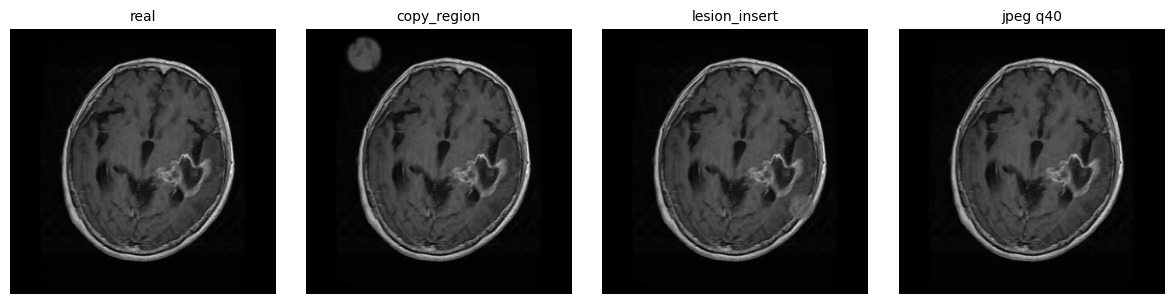

In [5]:
# quick look: real / copy / lesion / jpeg
sample = split_df[split_df.split == "test"].iloc[0]
real_path = sample.path
rel = Path(real_path).relative_to("data")
paths = [
    real_path,
    (out_root / "copy_region" / rel).as_posix(),
    (out_root / "lesion_insert" / rel).as_posix(),
    (out_root / "jpeg" / rel).as_posix(),
]
titles = ["real", "copy_region", "lesion_insert", "jpeg q40"]

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, path, title in zip(axes, paths, titles):
    ax.imshow(Image.open(path), cmap="gray")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()